In [47]:
import pandas as pd

In [48]:
df=pd.read_csv('../data/cars_clean.csv')
print(df.shape)


(3981, 12)


In [49]:
numeric_cols=df.select_dtypes(include=['int64','float64'])
print(numeric_cols.columns)

Index(['model_year', 'milage', 'price'], dtype='object')


In [50]:
categorical_cols=df.select_dtypes(include=['object'])
print(categorical_cols.columns)

Index(['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col',
       'int_col', 'accident', 'clean_title'],
      dtype='object')


In [51]:
print(df['engine'].head(10))

0    300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...
1                                 3.8L V6 24V GDI DOHC
2                                       3.5 Liter DOHC
3    354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...
4                           2.0L I4 16V GDI DOHC Turbo
5                                            2.4 Liter
6         292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel
7         282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel
8        311.0HP 3.5L V6 Cylinder Engine Gasoline Fuel
9          534.0HP Electric Motor Electric Fuel System
Name: engine, dtype: object


In [52]:
df['horspower']=df['engine'].str.extract(r'(\d+\.?d*)HP')
df['horspower']=pd.to_numeric(df['horspower'])

In [53]:
df['engine_size']=df['engine'].str.extract(r'(\d+\.?d*)L')
df['engine_size']=pd.to_numeric(df['engine_size'])

In [54]:
df['engine_type']=df['engine'].str.extract(r'(V\d+I]d+)')


In [55]:
print(df[["engine",'horspower','engine_size','engine_type']].head(10))

                                              engine  horspower  engine_size  \
0  300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...        0.0          7.0   
1                               3.8L V6 24V GDI DOHC        NaN          8.0   
2                                     3.5 Liter DOHC        NaN          NaN   
3  354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...        0.0          5.0   
4                         2.0L I4 16V GDI DOHC Turbo        NaN          0.0   
5                                          2.4 Liter        NaN          NaN   
6       292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel        0.0          0.0   
7       282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel        0.0          4.0   
8      311.0HP 3.5L V6 Cylinder Engine Gasoline Fuel        0.0          5.0   
9        534.0HP Electric Motor Electric Fuel System        0.0          NaN   

  engine_type  
0         NaN  
1         NaN  
2         NaN  
3         NaN  
4         NaN  
5         NaN  
6      

In [56]:
print(df['transmission'].value_counts())

transmission
A/T                                  1035
8-Speed A/T                           406
Transmission w/Dual Shift Mode        395
6-Speed A/T                           362
6-Speed M/T                           247
                                     ... 
10-Speed Automatic with Overdrive       1
9-Speed Automatic with Auto-Shift       1
SCHEDULED FOR OR IN PRODUCTION          1
6 Speed Mt                              1
8-Speed Manual                          1
Name: count, Length: 61, dtype: int64


In [57]:
def clean_transmiosn(value):
    if pd.isna(value):
        return 'Other'
    value = str(value).lower()
    if 'dual shift' in value:
        return 'Dual Shift'
    elif 'cvt' in value:
        return 'CVT'
    elif 'm/t' in value or 'manul' in value:
        return 'Manual'
    elif 'a/t' in value or 'automatic' in value:
        return 'Automatic'
    else:
        return 'Other'


In [58]:
df['transmission_clean']=df['transmission'].apply(clean_transmiosn)
print(df[['transmission','transmission_clean']].head(10))

        transmission transmission_clean
0        6-Speed A/T          Automatic
1  8-Speed Automatic          Automatic
2          Automatic          Automatic
3        7-Speed A/T          Automatic
4  8-Speed Automatic          Automatic
5                  F              Other
6        6-Speed A/T          Automatic
7                A/T          Automatic
8        6-Speed A/T          Automatic
9                A/T          Automatic


In [59]:
cols=['brand','fuel_type','accident','clean_title','engine_type','transmission_clean']
for col in cols:
    print(f'{col} :{df[col].nunique()}')

brand :56
fuel_type :8
accident :3
clean_title :2
engine_type :0
transmission_clean :5


In [60]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()

In [61]:
df['accident']=le.fit_transform(df['accident'])
df['clean_title']=le.fit_transform(df['clean_title'])
                                

In [62]:
df=pd.get_dummies(data=df,columns=['brand','fuel_type','engine_type','transmission_clean'])


In [63]:
df.drop(columns=['transmission','engine'],inplace=True)

In [65]:
correlation=df.corr(numeric_only=True)



In [68]:
print(correlation['price'].sort_values(ascending=False))

price                        1.000000
model_year                   0.442392
brand_Lamborghini            0.325827
brand_Porsche                0.226925
brand_Bentley                0.217975
                               ...   
transmission_clean_Manual   -0.080344
engine_size                 -0.086714
fuel_type_E85 Flex Fuel     -0.089468
clean_title                 -0.190033
milage                      -0.527571
Name: price, Length: 76, dtype: float64


In [69]:
import matplotlib.pyplot as plt
import seaborn as sns


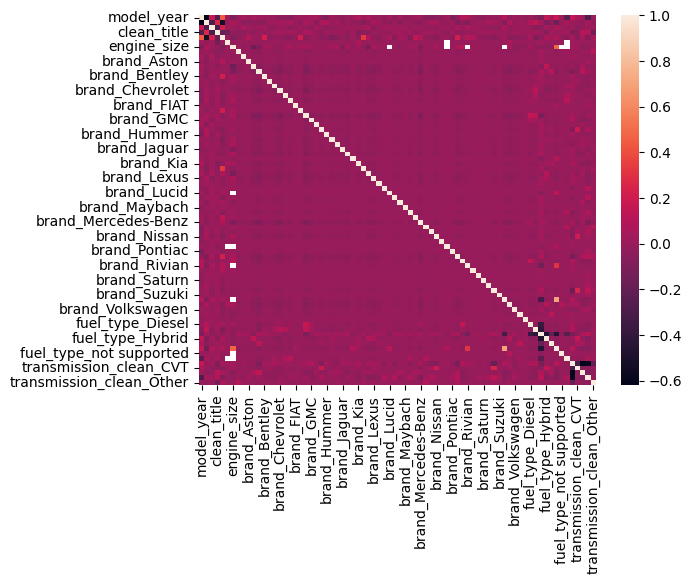

In [71]:
sns.heatmap(correlation)
plt.show()

In [72]:
print(len(df.columns))

79


In [74]:
df.to_csv('../data/cars_feature.csv',index=False)